<h4> Model 1 — Random Forest Classifier </h4>

<h4> Objective </h4>
The first predictive model is a Random Forest classifier for predicting whether an e-commerce order will be returned. The model uses the **feature-engineered dataset produced by Notebook 2 — Feature Engineering**. This ensures that the model is trained using the engineered variables created specifically for the STADIOalot return-prediction problem.

<h4> Model Input </h4>

The Random Forest model uses:
`data/processed/returns_features.csv`

This dataset is produced by:
`notebooks/02_FeatureEngineering.ipynb`

The target variable is:
`Return_Status`

where:
- `0` = Not Returned
- `1` = Returned

The model uses information available from the feature-engineered dataset and does not use post-return information that could cause data leakage.

<h4> Why Random Forest? </h4>
Random Forest is an ensemble learning method that combines multiple decision trees to perform classification. It was selected for this project because return behaviour may involve non-linear relationships between customer, product, transaction and other engineered characteristics.

<h4> Hyperparameters </h4>
The Random Forest classifier uses the following configuration:

| Parameter | Value |
|---|---:|
| `n_estimators` | 300 |
| `max_depth` | 12 |
| `min_samples_split` | 5 |
| `min_samples_leaf` | 2 |
| `class_weight` | `balanced_subsample` |
| `random_state` | 42 |
| `n_jobs` | -1 |

<h4> Train/Test Split </h4>

The feature-engineered dataset is divided into:

- **80% training data**
- **20% testing data**

A stratified split is used so that the proportion of returned and non-returned orders is preserved in both the training and testing datasets.

<h4> Model Preprocessing </h4>

The model uses a single Scikit-learn pipeline containing both preprocessing and the Random Forest classifier.

<h4> Numerical Features </h4>

Numerical features are processed using:

- Median imputation for missing values
- `StandardScaler` for numerical scaling

<h4> Categorical Features </h4>

Categorical features are processed using:

- Most-frequent imputation for missing values
- `OneHotEncoder`
- `handle_unknown="ignore"` so unseen categories do not cause prediction errors

The preprocessing is fitted only on the training data as part of the pipeline.

<h4> Model Evaluation </h4>

The model is evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix
- Classification report

These metrics provide multiple views of the model's ability to distinguish between returned and non-returned orders.

<h4> Model Output </h4>

The trained Random Forest pipeline is saved to:
`models/model1_random_forest.joblib`

The evaluation metrics are saved to:
`experimental_results/model1_random_forest_metrics.csv`

<h4> Model Workflow </h4>

```text
Feature-Engineered Dataset
        │
        │
        ▼
returns_features.csv
        │
        ▼
Separate Features (X)
and Target (y)
        │
        ▼
Stratified 80/20 Split
        │
        ├───────────────┐
        ▼               ▼
   Training Data    Testing Data
        │               │
        ▼               │
Numerical +             │
Categorical             │
Preprocessing           │
        │               │
        ▼               │
Random Forest           │
Classifier              │
        │               │
        ▼               ▼
      Predictions and Probabilities
                │
                ▼
          Model Evaluation
                │
        ┌───────┼────────┐
        ▼       ▼        ▼
     Metrics  Confusion  ROC-AUC
              Matrix
                │
                ▼
       Saved Model + Results

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES AND DEFINE PROJECT PATHS
# ============================================================

from pathlib import Path

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# DISPLAY SETTINGS
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)


# ============================================================
# PROJECT ROOT
# ============================================================

ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

ROOT = ROOT.resolve()


# ============================================================
# PROJECT PATHS
# ============================================================

# Input dataset
DATA_PATH = (
    ROOT
    / "data"
    / "processed"
    / "returns_features.csv"
)

# Saved Random Forest model
MODEL_PATH = (
    ROOT
    / "models"
    / "model1_random_forest.joblib"
)

# Saved evaluation metrics
RESULT_PATH = (
    ROOT
    / "experimental_results"
    / "model1_random_forest_metrics.csv"
)

# Visualisations folder
VISUALISATIONS_PATH = (
    ROOT
    / "visualisations"
)

# Saved Random Forest confusion matrix
CONFUSION_MATRIX_PATH = (
    VISUALISATIONS_PATH
    / "model1_random_forest_confusion_matrix.png"
)


# ============================================================
# CREATE REQUIRED OUTPUT FOLDERS
# ============================================================

# Create folders automatically if they do not already exist
MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

RESULT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

VISUALISATIONS_PATH.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# PATH SUMMARY TABLE
# ============================================================

path_summary = pd.DataFrame({
    "File": [
        "Feature Engineered Dataset",
        "Random Forest Model",
        "Random Forest Metrics",
        "Visualisations Folder",
        "Random Forest Confusion Matrix"
    ],
    
    "Purpose": [
        "Input dataset for Model 1",
        "Saved trained Random Forest pipeline",
        "Saved Model 1 evaluation metrics",
        "Folder containing Model 1 visualisations",
        "Saved Model 1 confusion matrix image"
    ],
    
    "Full Path": [
        str(DATA_PATH.resolve()),
        str(MODEL_PATH.resolve()),
        str(RESULT_PATH.resolve()),
        str(VISUALISATIONS_PATH.resolve()),
        str(CONFUSION_MATRIX_PATH.resolve())
    ]
})

print("Path Summary")
display(path_summary)

# ============================================================
# LOAD DATASET
# ============================================================

df = pd.read_csv(DATA_PATH)

# ============================================================
# 2. SEPARATE FEATURES AND TARGET
# ============================================================

if "Return_Status" not in df.columns:
    raise ValueError(
        "Target variable 'Return_Status' was not found."
    )


X = df.drop(
    columns=["Return_Status"]
)


y = df["Return_Status"].astype(int)


# ============================================================
# FEATURE AND TARGET SUMMARY
# ============================================================

feature_target_summary = pd.DataFrame({
    "Dataset Component": [
        "Features (X)",
        "Target (y)"
    ],
    "Rows": [
        X.shape[0],
        y.shape[0]
    ],
    "Columns": [
        X.shape[1],
        1
    ]
})

print("Feature Target Summary")
display(feature_target_summary)


Path Summary


,File,Purpose,Full Path
0,Feature Engineered Dataset,Input dataset for Model 1,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\processed\returns_features.csv
1,Random Forest Model,Saved trained Random Forest pipeline,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\model1_random_forest.joblib
2,Random Forest Metrics,Saved Model 1 evaluation metrics,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model1_random_forest_metrics.csv
3,Visualisations Folder,Folder containing Model 1 visualisations,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations
4,Random Forest Confusion Matrix,Saved Model 1 confusion matrix image,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\model1_random_forest_confusion_matrix.png


Feature Target Summary


,Dataset Component,Rows,Columns
0,Features (X),10000,19
1,Target (y),10000,1


In [2]:
# ============================================================
# 3. TRAIN / TEST SPLIT
# ============================================================

TEST_SIZE = 0.20
RANDOM_STATE = 42


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)


# ============================================================
# DISPLAY SPLIT INFORMATION
# ============================================================

split_summary = pd.DataFrame({
    "Dataset": [
        "Full Dataset",
        "Training Set",
        "Testing Set"
    ],
    "Rows": [
        len(X),
        len(X_train),
        len(X_test)
    ],
    "Percentage": [
        100.00,
        len(X_train) / len(X) * 100,
        len(X_test) / len(X) * 100
    ]
})

print("Split Summary")
display(split_summary)

# ============================================================
# 4. VERIFY TARGET DISTRIBUTION AFTER SPLIT
# ============================================================

train_distribution = (
    y_train
    .value_counts(normalize=True)
    .sort_index()
    * 100
)


test_distribution = (
    y_test
    .value_counts(normalize=True)
    .sort_index()
    * 100
)


split_target_report = pd.DataFrame({
    "Return Status": [
        0,
        1
    ],
    "Label": [
        "Not Returned",
        "Returned"
    ],
    "Training (%)": [
        train_distribution.get(0, 0),
        train_distribution.get(1, 0)
    ],
    "Testing (%)": [
        test_distribution.get(0, 0),
        test_distribution.get(1, 0)
    ]
})

print("Split Target Report")
display(split_target_report)

Split Summary


,Dataset,Rows,Percentage
0,Full Dataset,10000,100.0000
1,Training Set,8000,80.0000
2,Testing Set,2000,20.0000


Split Target Report


,Return Status,Label,Training (%),Testing (%)
0,0,Not Returned,49.4750,49.5000
1,1,Returned,50.5250,50.5000


In [3]:
# ============================================================
# 5. IDENTIFY FEATURE TYPES
# ============================================================

numeric_features = (
    X_train
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)


categorical_features = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)


# ============================================================
# FEATURE TYPE SUMMARY
# ============================================================

feature_type_summary = pd.DataFrame({
    "Feature Type": [
        "Numerical",
        "Categorical",
        "Total"
    ],
    "Number of Features": [
        len(numeric_features),
        len(categorical_features),
        len(numeric_features) + len(categorical_features)
    ]
})

print("Feature Type Summary")
display(feature_type_summary)

# ============================================================
# 6. NUMERICAL FEATURES
# ============================================================

if numeric_features:

    numerical_feature_table = pd.DataFrame({
        "Feature Number": range(
            1,
            len(numeric_features) + 1
        ),
        "Numerical Feature": numeric_features
    })

else:

    numerical_feature_table = pd.DataFrame({
        "Feature Number": [],
        "Numerical Feature": []
    })

print("Numerical Features")
display(numerical_feature_table)


# ============================================================
# 7. CATEGORICAL FEATURES
# ============================================================

if categorical_features:

    categorical_feature_table = pd.DataFrame({
        "Feature Number": range(
            1,
            len(categorical_features) + 1
        ),
        "Categorical Feature": categorical_features
    })

else:

    categorical_feature_table = pd.DataFrame({
        "Feature Number": [],
        "Categorical Feature": []
    })

print("Categorical Features")
display(categorical_feature_table)


Feature Type Summary


,Feature Type,Number of Features
0,Numerical,13
1,Categorical,6
2,Total,19


Numerical Features


,Feature Number,Numerical Feature
0,1,Product_Price
1,2,Order_Quantity
2,3,User_Age
3,4,Discount_Applied
4,5,order_year
5,6,order_month
6,7,order_day
7,8,order_day_of_week
8,9,order_week_of_year
9,10,order_is_weekend


Categorical Features


,Feature Number,Categorical Feature
0,1,Product_Category
1,2,User_Gender
2,3,User_Location
3,4,Payment_Method
4,5,Shipping_Method
5,6,age_band


In [4]:
# ============================================================
# 8. NUMERICAL PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


numeric_preprocessing_summary = pd.DataFrame({
    "Step": [
        "Missing-value handling",
        "Scaling"
    ],
    "Method": [
        "Median imputation",
        "StandardScaler"
    ],
    "Purpose": [
        "Replace missing numerical values",
        "Standardise numerical feature scale"
    ]
})

print("Numerical Preprocessing")
display(numeric_preprocessing_summary)

# ============================================================
# 9. CATEGORICAL PREPROCESSING PIPELINE
# ============================================================

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


categorical_preprocessing_summary = pd.DataFrame({
    "Step": [
        "Missing-value handling",
        "Categorical encoding"
    ],
    "Method": [
        "Most-frequent imputation",
        "One-hot encoding"
    ],
    "Purpose": [
        "Replace missing categorical values",
        "Convert categories into numerical features"
    ]
})

print("Categorical Preprocessing")
display(categorical_preprocessing_summary)

# ============================================================
# 10. COMBINED PREPROCESSING PIPELINE
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)


preprocessing_summary = pd.DataFrame({
    "Feature Type": [
        "Numerical",
        "Categorical"
    ],
    "Imputation": [
        "Median",
        "Most Frequent"
    ],
    "Transformation": [
        "StandardScaler",
        "OneHotEncoder"
    ],
    "Unknown Categories": [
        "Not applicable",
        "Ignored"
    ]
})

print("Combined Preprocessing Summary")
display(preprocessing_summary)

Numerical Preprocessing


,Step,Method,Purpose
0,Missing-value handling,Median imputation,Replace missing numerical values
1,Scaling,StandardScaler,Standardise numerical feature scale


Categorical Preprocessing


,Step,Method,Purpose
0,Missing-value handling,Most-frequent imputation,Replace missing categorical values
1,Categorical encoding,One-hot encoding,Convert categories into numerical features


Combined Preprocessing Summary


,Feature Type,Imputation,Transformation,Unknown Categories
0,Numerical,Median,StandardScaler,Not applicable
1,Categorical,Most Frequent,OneHotEncoder,Ignored


In [5]:
# ============================================================
# 11. RANDOM FOREST MODEL CONFIGURATION
# ============================================================

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)


model_configuration = pd.DataFrame({
    "Parameter": [
        "Model",
        "Number of Trees",
        "Maximum Depth",
        "Minimum Samples Split",
        "Minimum Samples Leaf",
        "Class Weight",
        "Random State",
        "Number of Jobs"
    ],
    "Value": [
        "Random Forest Classifier",
        300,
        12,
        5,
        2,
        "balanced_subsample",
        RANDOM_STATE,
        -1
    ]
})

print("Model Configuration")
display(model_configuration)

Model Configuration


,Parameter,Value
0,Model,Random Forest Classifier
1,Number of Trees,300
2,Maximum Depth,12
3,Minimum Samples Split,5
4,Minimum Samples Leaf,2
5,Class Weight,balanced_subsample
6,Random State,42
7,Number of Jobs,-1


In [6]:
# ============================================================
# 12. BUILD COMPLETE MODEL PIPELINE
# ============================================================

model_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            random_forest
        )
    ]
)


pipeline_summary = pd.DataFrame({
    "Pipeline Stage": [
        1,
        2
    ],
    "Component": [
        "Preprocessor",
        "Random Forest Classifier"
    ],
    "Purpose": [
        "Impute, scale and encode features",
        "Perform binary classification"
    ]
})


display(pipeline_summary)

,Pipeline Stage,Component,Purpose
0,1,Preprocessor,"Impute, scale and encode features"
1,2,Random Forest Classifier,Perform binary classification


In [7]:
# ============================================================
# 13. TRAIN RANDOM FOREST MODEL
# ============================================================

model_pipeline.fit(
    X_train,
    y_train
)


training_summary = pd.DataFrame({
    "Item": [
        "Model",
        "Training Rows",
        "Training Features",
        "Training Status"
    ],
    "Value": [
        "Random Forest",
        len(X_train),
        X_train.shape[1],
        "COMPLETED"
    ]
})

print("Training Summary")
display(training_summary)

# ============================================================
# 14. GENERATE TEST SET PREDICTIONS
# ============================================================

y_pred = model_pipeline.predict(
    X_test
)


y_probability = (
    model_pipeline
    .predict_proba(X_test)[:, 1]
)


prediction_summary = pd.DataFrame({
    "Prediction Output": [
        "Class Predictions",
        "Return Probabilities"
    ],
    "Rows": [
        len(y_pred),
        len(y_probability)
    ],
    "Generated": [
        "YES",
        "YES"
    ]
})

print("Prediction Summary")
display(prediction_summary)

Training Summary


,Item,Value
0,Model,Random Forest
1,Training Rows,8000
2,Training Features,19
3,Training Status,COMPLETED


Prediction Summary


,Prediction Output,Rows,Generated
0,Class Predictions,2000,YES
1,Return Probabilities,2000,YES


In [8]:
# ============================================================
# 15. PREDICTION PREVIEW
# ============================================================

prediction_preview = pd.DataFrame({
    "Actual Return Status": y_test.values,
    "Predicted Return Status": y_pred,
    "Return Probability": y_probability
})


prediction_preview["Actual Label"] = (
    prediction_preview["Actual Return Status"]
    .map({
        0: "Not Returned",
        1: "Returned"
    })
)


prediction_preview["Predicted Label"] = (
    prediction_preview["Predicted Return Status"]
    .map({
        0: "Not Returned",
        1: "Returned"
    })
)


prediction_preview = prediction_preview[
    [
        "Actual Return Status",
        "Actual Label",
        "Predicted Return Status",
        "Predicted Label",
        "Return Probability"
    ]
]

print("Prediction Preview")
display(prediction_preview.head(10))

Prediction Preview


,Actual Return Status,Actual Label,Predicted Return Status,Predicted Label,Return Probability
0,0,Not Returned,0,Not Returned,0.4977
1,1,Returned,1,Returned,0.5195
2,0,Not Returned,0,Not Returned,0.4701
3,1,Returned,0,Not Returned,0.4717
4,0,Not Returned,1,Returned,0.5230
5,0,Not Returned,0,Not Returned,0.4831
6,0,Not Returned,1,Returned,0.5292
7,1,Returned,0,Not Returned,0.4837
8,1,Returned,0,Not Returned,0.4196
9,1,Returned,0,Not Returned,0.4818


In [9]:
# ============================================================
# 16. MODEL EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)


recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)


f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


roc_auc = roc_auc_score(
    y_test,
    y_probability
)


metrics_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print("Metrics Table")
display(metrics_table)

# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

classification_results = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)


classification_table = pd.DataFrame(
    classification_results
).transpose()


classification_table = (
    classification_table
    .reset_index()
    .rename(
        columns={
            "index": "Class"
        }
    )
)


# Rename class labels
classification_table["Class"] = (
    classification_table["Class"]
    .replace({
        "0": "Not Returned",
        "1": "Returned",
        "accuracy": "Accuracy",
        "macro avg": "Macro Average",
        "weighted avg": "Weighted Average"
    })
)

print("Classification Report")
display(classification_table)

Metrics Table


,Metric,Score
0,Accuracy,0.5000
1,Precision,0.5048
2,Recall,0.5198
3,F1-Score,0.5122
4,ROC-AUC,0.4925


Classification Report


,Class,precision,recall,f1-score,support
0,Not Returned,0.4948,0.4798,0.4872,990.0000
1,Returned,0.5048,0.5198,0.5122,1010.0000
2,Accuracy,0.5000,0.5000,0.5000,0.5000
3,Macro Average,0.4998,0.4998,0.4997,2000.0000
4,Weighted Average,0.4998,0.5000,0.4998,2000.0000


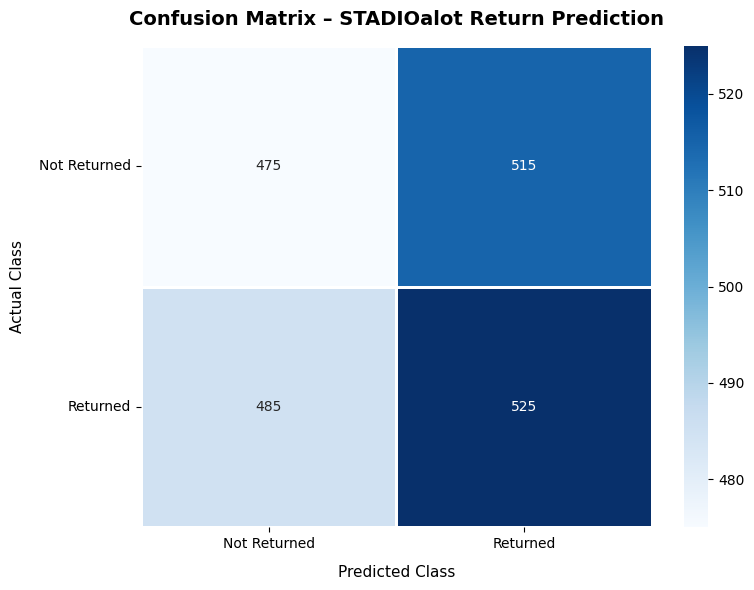

Confusion Matrix Summary


,Measure,Count,Meaning
0,True Negatives,475,Correctly predicted Not Returned
1,False Positives,515,Incorrectly predicted Returned
2,False Negatives,485,Missed a Returned order
3,True Positives,525,Correctly predicted Returned


Confusion Matrix Visualisation


,Visualisation,File Name,Full Path,Saved
0,Random Forest Confusion Matrix,model1_random_forest_confusion_matrix.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\model1_random_forest_confusion_matrix.png,True


In [10]:
# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

# Create visualisations folder if it does not already exist
VISUALISATIONS_PATH = ROOT / "visualisations"
VISUALISATIONS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# File path for the confusion matrix image
CONFUSION_MATRIX_PATH = (
    VISUALISATIONS_PATH
    / "model1_random_forest_confusion_matrix.png"
)


# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)


# Create readable labels
labels = [
    "Not Returned",
    "Returned"
]


# Create the figure
plt.figure(figsize=(8, 6))


# Create heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=1,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels
)


# Add title
plt.title(
    "Confusion Matrix – STADIOalot Return Prediction",
    fontsize=14,
    fontweight="bold",
    pad=15
)


# Add axis labels
plt.xlabel(
    "Predicted Class",
    fontsize=11,
    labelpad=10
)

plt.ylabel(
    "Actual Class",
    fontsize=11,
    labelpad=10
)


# Improve tick labels
plt.xticks(rotation=0)
plt.yticks(rotation=0)


# Adjust layout
plt.tight_layout()


# Save the displayed confusion matrix
plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)


# Display the confusion matrix
plt.show()


# ============================================================
# 19. CONFUSION MATRIX SUMMARY
# ============================================================

tn, fp, fn, tp = cm.ravel()


confusion_summary = pd.DataFrame({
    "Measure": [
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives"
    ],
    "Count": [
        tn,
        fp,
        fn,
        tp
    ],
    "Meaning": [
        "Correctly predicted Not Returned",
        "Incorrectly predicted Returned",
        "Missed a Returned order",
        "Correctly predicted Returned"
    ]
})

print("Confusion Matrix Summary")
display(confusion_summary)

# Confirm that the image was saved
visualisation_summary = pd.DataFrame({
    "Visualisation": [
        "Random Forest Confusion Matrix"
    ],
    "File Name": [
        CONFUSION_MATRIX_PATH.name
    ],
    "Full Path": [
        str(CONFUSION_MATRIX_PATH.resolve())
    ],
    "Saved": [
        CONFUSION_MATRIX_PATH.exists()
    ]
})

print("Confusion Matrix Visualisation")
display(visualisation_summary)


In [11]:
# ============================================================
# 20. SAVE MODEL METRICS
# ============================================================

metrics = pd.DataFrame([
    {
        "model": "Random Forest",
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": roc_auc
    }
])


# Create results directory if it does not exist
RESULT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# Save metrics
metrics.to_csv(
    RESULT_PATH,
    index=False
)


# ============================================================
# DISPLAY SAVE REPORT
# ============================================================

metrics_save_report = pd.DataFrame({
    "Item": [
        "Results File",
        "Full Results Path",
        "Rows Saved",
        "File Exists"
    ],
    "Value": [
        RESULT_PATH.name,
        str(RESULT_PATH.resolve()),
        len(metrics),
        RESULT_PATH.exists()
    ]
})


# Prevent pandas from truncating the file path
with pd.option_context(
    "display.max_colwidth", None
):
    display(metrics_save_report)

,Item,Value
0,Results File,model1_random_forest_metrics.csv
1,Full Results Path,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model1_random_forest_metrics.csv
2,Rows Saved,1
3,File Exists,True


In [12]:
# ============================================================
# 21. SAVE TRAINED MODEL
# ============================================================

MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# Save trained model pipeline
joblib.dump(
    model_pipeline,
    MODEL_PATH
)


# ============================================================
# DISPLAY MODEL SAVE REPORT
# ============================================================

model_save_report = pd.DataFrame({
    "Item": [
        "Model File",
        "Full Model Path",
        "Model Type",
        "File Exists"
    ],
    "Value": [
        MODEL_PATH.name,
        str(MODEL_PATH.resolve()),
        "Random Forest Pipeline",
        MODEL_PATH.exists()
    ]
})


# Prevent pandas from truncating the full path
with pd.option_context(
    "display.max_colwidth", None
):
    print("Model Save Report")
    display(model_save_report)

Model Save Report


,Item,Value
0,Model File,model1_random_forest.joblib
1,Full Model Path,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\model1_random_forest.joblib
2,Model Type,Random Forest Pipeline
3,File Exists,True


In [13]:
# ============================================================
# 22. FINAL MODEL SUMMARY
# ============================================================

final_model_summary = pd.DataFrame({
    "Item": [
        "Model",
        "Training Rows",
        "Testing Rows",
        "Number of Input Features",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Value": [
        "Random Forest",
        len(X_train),
        len(X_test),
        X.shape[1],
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4),
        round(roc_auc, 4)
    ]
})

print("Final Model Summary")
display(final_model_summary)

# ============================================================
# 23. FINAL MODEL VALIDATION
# ============================================================

validation_checks = pd.DataFrame({
    "Validation Check": [
        "Training completed",
        "Test predictions generated",
        "Prediction probabilities generated",
        "Accuracy calculated",
        "ROC-AUC calculated",
        "Metrics file saved",
        "Model file saved"
    ],
    "Result": [
        hasattr(model_pipeline, "classes_"),
        len(y_pred) == len(y_test),
        len(y_probability) == len(y_test),
        not np.isnan(accuracy),
        not np.isnan(roc_auc),
        RESULT_PATH.exists(),
        MODEL_PATH.exists()
    ]
})


validation_checks["Status"] = np.where(
    validation_checks["Result"],
    "PASS",
    "CHECK"
)

print("Validation Checks")
display(validation_checks)

# ============================================================
# 24. MODEL 1 — RANDOM FOREST COMPLETION SUMMARY
# ============================================================

completion_summary = pd.DataFrame({
    "Item": [
        "Model",
        "Process",
        "Status",
        "Input Dataset",
        "Model Output",
        "Metrics Output",
        "Visualisations Folder",
        "Confusion Matrix Output"
    ],
    
    "Value": [
        "Random Forest Classifier",
        "Training and Evaluation",
        "COMPLETE",
        str(DATA_PATH.resolve()),
        str(MODEL_PATH.resolve()),
        str(RESULT_PATH.resolve()),
        str(VISUALISATIONS_PATH.resolve()),
        str(CONFUSION_MATRIX_PATH.resolve())
    ]
})


print("Model 1 — Random Forest Complete")
display(completion_summary)

Final Model Summary


,Item,Value
0,Model,Random Forest
1,Training Rows,8000
2,Testing Rows,2000
3,Number of Input Features,19
4,Accuracy,0.5000
5,Precision,0.5048
6,Recall,0.5198
7,F1-Score,0.5122
8,ROC-AUC,0.4925


Validation Checks


,Validation Check,Result,Status
0,Training completed,True,PASS
1,Test predictions generated,True,PASS
2,Prediction probabilities generated,True,PASS
3,Accuracy calculated,True,PASS
4,ROC-AUC calculated,True,PASS
5,Metrics file saved,True,PASS
6,Model file saved,True,PASS


Model 1 — Random Forest Complete


,Item,Value
0,Model,Random Forest Classifier
1,Process,Training and Evaluation
2,Status,COMPLETE
3,Input Dataset,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\processed\returns_features.csv
4,Model Output,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\model1_random_forest.joblib
5,Metrics Output,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\model1_random_forest_metrics.csv
6,Visualisations Folder,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations
7,Confusion Matrix Output,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\model1_random_forest_confusion_matrix.png
